# 02 — Building the Combined Dataset

**Machine Learning vs Regression for COVID-19 Case Prediction via Wastewater-Based Epidemiology**
Sebastian Munteanu · Department of Mathematical Sciences, University of Bath

---

This notebook takes the bridge from notebook 01 and uses it to build the dataset everything else runs on: one row per **local authority per day**, from 1 June to 20 September 2021, with the wastewater signal and the case counts side by side.

Building it is only half the job. A pipeline that runs is not necessarily a pipeline that is correct, and the joins involved here are exactly the kind that fail quietly. So §6 takes several finished values, works them out again **by hand from the raw files**, and checks the two agree. The arithmetic is written out in full so it can be followed line by line. If any check fails, the notebook stops.

## Decisions made in this notebook

| Decision | Choice | Why | Alternative |
|---|---|---|---|
| Combining several works into one authority figure | Keep both the population-weighted **arithmetic** and **geometric** mean | 61% of authority-days draw on two or more works, and the two means differ by a factor of 3 at the 90th percentile. The choice matters, so it is better settled with evidence later than guessed now | Pick one now |
| `tLOD` (below the detection limit) | Substitute **LOD/2 = 80 gc/L** | Standard practice in the wastewater literature, and it keeps every value positive so the log scale stays usable | Substitute the full LOD, or zero |
| Days with no sample | Leave **missing**, and supply a trailing 7-day mean as a separate column | No invented observations in the dataset itself, but a smoothed column is available for models that need one | Interpolate within each works |
| Weighting when only some works report | Reweight over the works that did report | Uses all the information available that day | Require every works to report |
| Denominator for case rates | Recomputed from ONS mid-2019 populations | The published rate cannot be summed across merged districts (§4.2) | Use the published rate |

The fourth row carries an assumption worth being explicit about: reweighting treats the sampled part of an authority as representative of the whole. The `coverage_frac` column records how much of each authority's population was actually sampled, so this can be tested rather than assumed — models can be refitted on well-covered authorities only.

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option('display.width', 140)

# ---------------------------------------------------------------------------
# Paths. Nothing here needs editing: the project root is found automatically,
# whether the notebook is run from the notebooks/ folder or from the root.
# ---------------------------------------------------------------------------
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATA = PROJECT / 'data'          # all input files live here
OUT  = PROJECT / 'output'        # everything the notebooks produce goes here
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f'Could not find a data folder at {DATA} - run this notebook from inside the project folder'

STUDY_START, STUDY_END = '2021-06-01', '2021-09-20'
LOD, LOD_SUBSTITUTE = 160.0, 80.0          # gc/L
REPORTING_FOLD = {'E09000001': 'E09000012', 'E06000053': 'E06000052'}
fold = lambda c: REPORTING_FOLD.get(c, c)

bridge = pd.read_csv(OUT / 'stw_ltla_bridge.csv')
bridge = bridge[bridge.LAD21CD.str.startswith('E')].copy()
crosswalk = pd.read_csv(OUT / 'lad11_to_lad21.csv')
lad_map = dict(zip(crosswalk.LAD11CD, crosswalk.LAD21CD))

print(f'bridge: {len(bridge):,} STW-LTLA pairs | {bridge.uwwCode.nunique()} STWs | {bridge.LAD21CD.nunique()} LTLAs')

bridge: 2,321 STW-LTLA pairs | 1461 STWs | 307 LTLAs


### 1.1 What a wastewater reading actually is

Each number in this dataset is the concentration of SARS-CoV-2 genetic material found in a sample of untreated sewage arriving at a treatment works, measured in gene copies per litre.

The logic behind using it is that infected people shed viral RNA regardless of whether they ever take a test, feel ill, or report anything. So sewage gives a measure of infection in a population that does not depend on testing behaviour — which is exactly what makes case counts hard to interpret.

The catch is that concentration depends on more than how many people are infected. Rainfall dilutes it, industrial discharge affects it, and how long the sewage has been in the pipes affects how much of the RNA has degraded. That is part of why the relationship between concentration and cases turns out to be noisy and less than proportional.

Each cell in the source spreadsheet is one of three things, and they mean different things:

| Cell content | Meaning | How it is handled |
|---|---|---|
| A number | Concentration measured, in gc/L | Used directly |
| `tLOD` | A sample was tested but the concentration was too low to quantify (under 160 gc/L) | Replaced with 80 gc/L, half the detection limit — standard practice in this literature |
| Blank | No sample was taken at that works that day | Left missing. This is not a measurement of zero. |

## 2. Reshape the RNA data to long format

The EMHP `Daily_concentrations` sheet is wide: one row per STW, one column per day. Three things to handle.

**The sheet has 111 date columns, not 112.** `2021-07-17` is absent from the file entirely — the column does not exist, rather than existing and being empty. Building a 112-day range and reindexing onto it would silently manufacture a fully-missing day; the assertion below pins this down so it can't pass unnoticed.

**Three cell states, not two.** A numeric concentration, the string `tLOD` (a sample was taken and the result fell below the 160 gc/L detection limit), or blank (no sample taken). These mean different things and must not collapse into one another: `tLOD` is information, blank is absence of information.

**Half the grid is blank.** Sites are sampled a few times a week. The RNA series is inherently sparse and that sparsity is a property of the data, not a defect to be cleaned away.

In [2]:
xl = pd.ExcelFile(DATA / 'Final_EMHP_concentration_October_2021_data.ods', engine='odf')
daily = xl.parse('Daily_concentrations', skiprows=2)
daily.columns = daily.iloc[0]
daily = daily[1:].reset_index(drop=True)

date_cols = [c for c in daily.columns if str(c).startswith('2021')]
expected  = pd.date_range(STUDY_START, STUDY_END).strftime('%Y-%m-%d')
absent    = sorted(set(expected) - {str(c) for c in date_cols})

print(f'date columns present : {len(date_cols)} of {len(expected)} calendar days')
print(f'absent from the file : {absent}')
assert absent == ['2021-07-17'], f'unexpected absent dates: {absent}'

date columns present : 111 of 112 calendar days
absent from the file : ['2021-07-17']


In [3]:
rna = daily.melt(id_vars=['Site code'], value_vars=date_cols,
                 var_name='date', value_name='raw').rename(columns={'Site code': 'uwwCode'})
rna['raw'] = rna.raw.astype(str).str.strip()

rna['below_lod'] = rna.raw.eq('tLOD')
numeric          = pd.to_numeric(rna.raw, errors='coerce')
rna['no_sample'] = numeric.isna() & ~rna.below_lod

n_cells = len(rna)
print(f'total cells   : {n_cells:,}')
print(f'  numeric     : {numeric.notna().sum():,} ({100*numeric.notna().mean():.1f}%)')
print(f'  tLOD        : {rna.below_lod.sum():,} ({100*rna.below_lod.mean():.1f}%)')
print(f'  no sample   : {rna.no_sample.sum():,} ({100*rna.no_sample.mean():.1f}%)')
assert n_cells == numeric.notna().sum() + rna.below_lod.sum() + rna.no_sample.sum(), 'cell states do not partition'

rna['rna'] = np.where(rna.below_lod, LOD_SUBSTITUTE, numeric)
rna = rna[rna.rna.notna()].copy()
rna['date'] = pd.to_datetime(rna.date)

print(f'\nRNA observations retained: {len(rna):,} '
      f'({rna.below_lod.sum():,} = {100*rna.below_lod.mean():.1f}% at the detection limit)')
print(f'concentration range: {rna.rna.min():,.0f} to {rna.rna.max():,.0f} gc/L')

total cells   : 29,859
  numeric     : 11,974 (40.1%)
  tLOD        : 2,962 (9.9%)
  no sample   : 14,923 (50.0%)

RNA observations retained: 14,936 (2,962 = 19.8% at the detection limit)
concentration range: 80 to 1,879,113 gc/L


## 3. Apply the bridge — from STW to LTLA

For LTLA $\ell$ on day $t$, let $S_{\ell,t}$ be the STWs serving $\ell$ that reported that day, with bridge weights $w_{s\ell}$ (`shared_population`) and concentrations $x_{s,t}$:

$$
\bar{x}^{\text{arith}}_{\ell,t}=\frac{\sum_{s \in S_{\ell,t}} w_{s\ell}\,x_{s,t}}{\sum_{s \in S_{\ell,t}} w_{s\ell}}
\qquad\qquad
\bar{x}^{\text{geom}}_{\ell,t}=10^{\,\frac{\sum_{s} w_{s\ell}\log_{10} x_{s,t}}{\sum_{s} w_{s\ell}}}
$$

The arithmetic mean is the mass-balance quantity: roughly the concentration you would measure if the LTLA's sewage were pooled. The geometric mean matches the scale the data actually occupies — concentrations here span four orders of magnitude — and the sub-linear power law relating RNA to cases reported by Faraway et al. (2022).

Note that the denominator runs over $S_{\ell,t}$, the reporting STWs, not all STWs serving $\ell$. Coverage therefore varies day to day, and `coverage_frac` records it.

In [4]:
j = rna.merge(bridge[['uwwCode', 'LAD21CD', 'shared_population']], on='uwwCode')
j['w']   = j.shared_population
j['wx']  = j.w * j.rna
j['wlx'] = j.w * np.log10(j.rna)

rna_ltla = (j.groupby(['LAD21CD', 'date'])
              .agg(w=('w', 'sum'), wx=('wx', 'sum'), wlx=('wlx', 'sum'),
                   n_stw=('uwwCode', 'nunique'), n_below=('below_lod', 'sum'))
              .reset_index())
rna_ltla['rna_arith']   = rna_ltla.wx  / rna_ltla.w
rna_ltla['rna_geom']    = 10 ** (rna_ltla.wlx / rna_ltla.w)
rna_ltla['pop_sampled'] = rna_ltla.w
rna_ltla = rna_ltla[['LAD21CD', 'date', 'rna_arith', 'rna_geom', 'n_stw', 'n_below', 'pop_sampled']]

# the geometric mean can never exceed the arithmetic mean (AM-GM inequality)
assert (rna_ltla.rna_geom <= rna_ltla.rna_arith * (1 + 1e-9)).all(), 'AM-GM violated'

multi = rna_ltla[rna_ltla.n_stw > 1]
print(f'LTLA-day RNA cells : {len(rna_ltla):,} across {rna_ltla.LAD21CD.nunique()} LTLAs')
print(f'  fed by >1 STW    : {len(multi):,} ({100*len(multi)/len(rna_ltla):.0f}%) '
      f'| mean {rna_ltla.n_stw.mean():.2f}, max {rna_ltla.n_stw.max()} STWs')
ratio = multi.rna_arith / multi.rna_geom
print(f'  arith/geom ratio : median {ratio.median():.3f} | p90 {ratio.quantile(.9):.2f} '
      f'| p99 {ratio.quantile(.99):.1f} | max {ratio.max():.0f}')

LTLA-day RNA cells : 17,955 across 299 LTLAs
  fed by >1 STW    : 11,009 (61%) | mean 2.05, max 10 STWs
  arith/geom ratio : median 1.064 | p90 3.00 | p99 19.3 | max 175


## 4. Case data

### 4.1 Explicit date parsing

The three `ltla_newCases*` files **do not share a date format**: `newCasesBySpecimenDate` and `RollingRate` are `DD/MM/YYYY`, while `RollingSum` is `YYYY-MM-DD`. Letting pandas infer would transpose day and month in some rows of some files and not others — a corruption that produces plausible-looking dates and so would not announce itself. Each file is parsed with its own explicit format, and the study window is checked to contain all 112 days.

In [5]:
CASE_FILES = {
    'cases'           : ('ltla_newCasesBySpecimenDate.csv',            '%d/%m/%Y'),
    'cases_roll7_sum' : ('ltla_newCasesBySpecimenDateRollingSum.csv',  '%Y-%m-%d'),
    'cases_roll7_rate_published': ('ltla_newCasesBySpecimenDateRollingRate.csv', '%d/%m/%Y'),
}

def load_cases(fname, fmt, colname):
    c = pd.read_csv(DATA / fname, usecols=['date', 'area_code', 'value'])
    c = c[c.area_code.str.startswith('E')].copy()
    c['date'] = pd.to_datetime(c['date'], format=fmt)
    c = c[c.date.between(STUDY_START, STUDY_END)].copy()
    c['LAD21CD'] = c.area_code.map(lad_map).fillna(c.area_code).map(fold)
    return c

raw_cases = {k: load_cases(f, fmt, k) for k, (f, fmt) in CASE_FILES.items()}
for k, v in raw_cases.items():
    print(f'{k:28s} rows {len(v):>7,} | LTLA codes {v.LAD21CD.nunique():>3} | days {v.date.nunique()}')
    assert v.date.nunique() == 112, f'{k}: expected 112 days'

cases                        rows  35,280 | LTLA codes 307 | days 112
cases_roll7_sum              rows  35,280 | LTLA codes 307 | days 112
cases_roll7_rate_published   rows  35,280 | LTLA codes 307 | days 112


### 4.2 Why the published rolling *rate* is recomputed

Counts and sums are additive, so harmonising Buckinghamshire's four legacy districts onto `E06000060` is a matter of summing them. A **rate per 100,000** is not additive — summing four district rates gives roughly four times the true county rate. Up to 4 source codes merge into one harmonised LTLA here, so the published rate column cannot be carried through the harmonisation unchanged.

The rate is therefore recomputed as $10^5 \times \text{7-day sum} / \text{LTLA population}$, with the population aggregated from the same ONS mid-2019 LSOA estimates used throughout.

This is also an opportunity: on the ~300 LTLAs that were *not* reorganised, the published rate passes through untouched, so the recomputed rate can be checked against it. Agreement there validates the harmonisation, the population aggregation and the date parsing in one shot.

In [6]:
lsoa_lad = pd.read_excel(DATA / 'LSOA11_WD21_LAD21_EW_LU_V2.xlsx',
                         sheet_name='LSOA11_WD21_LAD21_EW_LU')[['LSOA11CD', 'LAD21CD']]
lsoa_pop = (pd.read_excel(DATA / 'SAPE22DT2-mid-2019-lsoa-syoa-estimates-unformatted.xlsx',
                          sheet_name='Mid-2019 Persons', skiprows=4)[['LSOA Code', 'All Ages']]
              .rename(columns={'LSOA Code': 'LSOA11CD', 'All Ages': 'population'})
              .dropna(subset=['LSOA11CD']))

_p = lsoa_lad.merge(lsoa_pop, on='LSOA11CD')
_p['LAD21CD'] = _p.LAD21CD.map(fold)
ltla_pop = _p.groupby('LAD21CD', as_index=False)['population'].sum().rename(columns={'population': 'ltla_pop'})
print(f'LTLA populations: {len(ltla_pop)} areas, {ltla_pop.ltla_pop.sum():,.0f} people')

/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


LTLA populations: 329 areas, 59,439,840 people


In [7]:
# --- cross-check recomputed vs published rate on LTLAs untouched by reorganisation
unchanged = set(crosswalk[crosswalk.LAD11CD == crosswalk.LAD21CD].LAD21CD)

_s = raw_cases['cases_roll7_sum'].groupby(['LAD21CD','date'], as_index=False)['value'].sum().rename(columns={'value':'sum7'})
_r = raw_cases['cases_roll7_rate_published'].groupby(['LAD21CD','date'], as_index=False)['value'].sum().rename(columns={'value':'rate7_pub'})
chk = _s.merge(_r, on=['LAD21CD','date']).merge(ltla_pop, on='LAD21CD')
chk = chk[chk.LAD21CD.isin(unchanged)].copy()
chk['rate7_mine'] = 100_000 * chk.sum7 / chk.ltla_pop
chk['rel_err']    = (chk.rate7_mine - chk.rate7_pub) / chk.rate7_pub.replace(0, np.nan)

print(f'recomputed vs published rolling rate, {len(chk):,} unreorganised LTLA-days:')
print(f'  median relative error : {chk.rel_err.median()*100:+.2f}%')
print(f'  5th - 95th percentile : {chk.rel_err.quantile(.05)*100:+.2f}% to {chk.rel_err.quantile(.95)*100:+.2f}%')
assert abs(chk.rel_err.median()) < 0.02, 'recomputed rate disagrees with published rate'

recomputed vs published rolling rate, 32,816 unreorganised LTLA-days:
  median relative error : +0.39%
  5th - 95th percentile : -0.31% to +1.59%


The small positive offset is expected and explicable rather than mysterious: UKHSA computed its rates against **mid-2020** ONS population estimates, while this pipeline uses **mid-2019** (chosen in notebook 01 to match the vintage EMHP used for catchment populations). England's population grew slightly over that year, so a marginally smaller denominator gives a marginally larger rate. A sub-1% discrepancy of the expected sign is a pass.

## 5. Assemble the panel

In [8]:
cases = (raw_cases['cases'].groupby(['LAD21CD','date'], as_index=False)['value']
         .sum().rename(columns={'value':'cases'}))
sum7  = (raw_cases['cases_roll7_sum'].groupby(['LAD21CD','date'], as_index=False)['value']
         .sum().rename(columns={'value':'cases_roll7_sum'}))
assert cases.cases.sum() == raw_cases['cases'].value.sum(), 'cases lost in harmonisation'

# complete LTLA x day skeleton, so absent rows are visibly absent
ltlas = sorted(cases.LAD21CD.unique())
panel = (pd.MultiIndex.from_product([ltlas, pd.date_range(STUDY_START, STUDY_END)],
                                    names=['LAD21CD','date']).to_frame(index=False)
         .merge(cases,    on=['LAD21CD','date'], how='left')
         .merge(sum7,     on=['LAD21CD','date'], how='left')
         .merge(rna_ltla, on=['LAD21CD','date'], how='left')
         .merge(ltla_pop, on='LAD21CD',          how='left'))

# a missing row in newCasesBySpecimenDate means zero cases that day, not unknown
panel['cases'] = panel.cases.fillna(0)

panel['cases_roll7_rate'] = 100_000 * panel.cases_roll7_sum / panel.ltla_pop
panel['coverage_frac']    = panel.pop_sampled / panel.ltla_pop
panel['log10_rna_arith']  = np.log10(panel.rna_arith)
panel['log10_rna_geom']   = np.log10(panel.rna_geom)

panel = panel.sort_values(['LAD21CD','date'])
for c in ['rna_arith','rna_geom']:
    panel[c + '_roll7'] = panel.groupby('LAD21CD')[c].transform(
        lambda s: s.rolling(7, min_periods=1).mean())

names = bridge[['LAD21CD','LAD21NM']].drop_duplicates('LAD21CD')
panel = panel.merge(names, on='LAD21CD', how='left')

panel = panel[['LAD21CD','LAD21NM','date','cases','cases_roll7_sum','cases_roll7_rate',
               'rna_arith','rna_geom','log10_rna_arith','log10_rna_geom',
               'rna_arith_roll7','rna_geom_roll7',
               'n_stw','n_below','pop_sampled','ltla_pop','coverage_frac']].reset_index(drop=True)

assert len(panel) == len(ltlas) * 112, 'panel is not a complete LTLA x day grid'
print(f'PANEL {panel.shape[0]:,} rows x {panel.shape[1]} cols  '
      f'({panel.LAD21CD.nunique()} LTLAs x {panel.date.nunique()} days)')
print(f'  rows with same-day RNA : {panel.rna_arith.notna().sum():,} ({100*panel.rna_arith.notna().mean():.1f}%)')
print(f'  rows with 7-day RNA    : {panel.rna_arith_roll7.notna().sum():,} ({100*panel.rna_arith_roll7.notna().mean():.1f}%)')
print(f'  total cases            : {panel.cases.sum():,.0f}')
display(panel.head())

PANEL 34,384 rows x 17 cols  (307 LTLAs x 112 days)
  rows with same-day RNA : 17,955 (52.2%)
  rows with 7-day RNA    : 32,988 (95.9%)
  total cases            : 2,543,938


,LAD21CD,LAD21NM,date,cases,cases_roll7_sum,cases_roll7_rate,rna_arith,rna_geom,log10_rna_arith,log10_rna_geom,rna_arith_roll7,rna_geom_roll7,n_stw,n_below,pop_sampled,ltla_pop,coverage_frac
0,E06000001,Hartlepool,2021-06-01,0,6,6.405945,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93663,NaN
1,E06000001,Hartlepool,2021-06-02,1,4,4.270630,1561.385045,1502.4285,3.19351,3.176794,1561.385045,1502.42850,2.0,1.0,92793.451061,93663,0.990716
2,E06000001,Hartlepool,2021-06-03,0,3,3.202972,NaN,NaN,NaN,NaN,1561.385045,1502.42850,NaN,NaN,NaN,93663,NaN
3,E06000001,Hartlepool,2021-06-04,2,4,4.270630,80.000000,80.0000,1.90309,1.903090,820.692523,791.21425,1.0,1.0,1758.463834,93663,0.018774
4,E06000001,Hartlepool,2021-06-05,3,7,7.473602,NaN,NaN,NaN,NaN,820.692523,791.21425,NaN,NaN,NaN,93663,NaN


In [9]:
print('LTLAs with cases but never any RNA signal:')
never = panel.groupby(['LAD21CD','LAD21NM']).rna_arith.count()
display(never[never == 0].reset_index()[['LAD21CD','LAD21NM']])
print('These have no EMHP-sampled STW in their catchment and will drop out of any model.')

LTLAs with cases but never any RNA signal:


,LAD21CD,LAD21NM
0,E06000043,Brighton and Hove
1,E07000029,Copeland
2,E07000035,Derbyshire Dales
3,E07000041,Exeter
4,E07000046,Torridge
5,E07000047,West Devon
6,E07000199,Tamworth
7,E08000009,Trafford


These have no EMHP-sampled STW in their catchment and will drop out of any model.


## 6. Checking the results by hand

Everything above is machinery, and machinery can be wrong in ways that produce plausible-looking numbers. This section takes four finished values and works them out again directly from the raw spreadsheet and CSVs, printing the arithmetic step by step, then checks they match.

None of these checks reuse the aggregation code from §3. They are written separately, so a mistake in the pipeline shows up as a disagreement rather than being repeated identically on both sides.

Four situations are covered on purpose:

1. an authority served by a **single** works — checks the plumbing end to end
2. an authority served by **several** works — checks the population weighting
3. a cell containing a **`tLOD`** reading — checks the substitution
4. an authority affected by a **boundary change** — checks the case harmonisation

In [10]:
# helper: pull one raw cell straight out of the spreadsheet
raw_lookup = daily.set_index('Site code')

def raw_cell(stw, datestr):
    col = [c for c in daily.columns if str(c) == datestr][0]
    return str(raw_lookup.loc[stw, col]).strip()

def contributing(ltla, datestr):
    # STWs serving `ltla` that reported on `datestr`, with their raw values
    served = bridge[bridge.LAD21CD == ltla][['uwwCode','uwwName','shared_population']]
    served = served[served.uwwCode.isin(raw_lookup.index)]   # only EMHP-sampled works appear in the sheet
    rows = []
    for _, r in served.iterrows():
        v = raw_cell(r.uwwCode, datestr)
        if v not in ('nan','','None'):
            rows.append({'uwwCode': r.uwwCode, 'uwwName': r.uwwName,
                         'weight': r.shared_population, 'raw': v,
                         'value': LOD_SUBSTITUTE if v == 'tLOD' else float(v)})
    return pd.DataFrame(rows)

def check(ltla, datestr, label):
    print(f'--- {label}\n    {ltla}  {datestr}')
    con = contributing(ltla, datestr)
    display(con)

    W  = con.weight.sum()
    am = sum(r.weight * r.value       for _, r in con.iterrows()) / W
    gm = 10 ** (sum(r.weight * np.log10(r.value) for _, r in con.iterrows()) / W)

    terms = ' + '.join(f'{r.weight:,.0f}x{r.value:,.0f}' for _, r in con.iterrows())
    print(f'    by hand  arithmetic = ({terms}) / {W:,.0f} = {am:,.2f}')
    print(f'    by hand  geometric  = {gm:,.2f}')

    row = panel[(panel.LAD21CD == ltla) & (panel.date == datestr)].iloc[0]
    print(f'    pipeline arithmetic = {row.rna_arith:,.2f}   geometric = {row.rna_geom:,.2f}   n_stw = {row.n_stw:.0f}')

    assert np.isclose(am, row.rna_arith), f'arithmetic mismatch: {am} vs {row.rna_arith}'
    assert np.isclose(gm, row.rna_geom),  f'geometric mismatch: {gm} vs {row.rna_geom}'
    assert len(con) == row.n_stw,         f'STW count mismatch: {len(con)} vs {row.n_stw}'
    print('    PASS\n')

In [11]:
# pick concrete examples from the panel rather than hard-coding guesses
single = panel[(panel.n_stw == 1) & panel.rna_arith.notna()].iloc[0]
multi_ = panel[(panel.n_stw >= 3) & panel.rna_arith.notna()].sort_values('n_stw', ascending=False).iloc[0]
tlod   = panel[(panel.n_below >= 1) & (panel.n_stw >= 2)].iloc[0]

check(single.LAD21CD, single.date.strftime('%Y-%m-%d'), 'CASE 1 — single contributing STW')
check(multi_.LAD21CD, multi_.date.strftime('%Y-%m-%d'), 'CASE 2 — several STWs, population weighted')
check(tlod.LAD21CD,   tlod.date.strftime('%Y-%m-%d'),   'CASE 3 — includes a tLOD reading substituted at LOD/2')

--- CASE 1 — single contributing STW
    E06000001  2021-06-04


,uwwCode,uwwName,weight,raw,value
0,UKENNE_NU_TP000009,BILLINGHAM STW,1758.463834,tLOD,80.0


    by hand  arithmetic = (1,758x80) / 1,758 = 80.00
    by hand  geometric  = 80.00
    pipeline arithmetic = 80.00   geometric = 80.00   n_stw = 1
    PASS

--- CASE 2 — several STWs, population weighted
    E06000052  2021-06-28


,uwwCode,uwwName,weight,raw,value
0,UKENSW_SWS_TP000005,BODMIN (SCARLETTS WELL) STW,8449.229823,tLOD,80.0
1,UKENSW_SWS_TP000010,CAMBORNE / REDRUTH STW,55442.594903,tLOD,80.0
2,UKENSW_SWS_TP000022,ERNESETTLE AND SALTASH STW,16547.815590,1469,1469.0
3,UKENSW_SWS_TP000025,FALMOUTH STW,40000.804954,12170,12170.0
4,UKENSW_SWS_TP000031,ST IVES AND PENZANCE STW,56215.984170,tLOD,80.0
5,UKENSW_SWS_TP000033,HELSTON STW,12181.703418,tLOD,80.0
6,UKENSW_SWS_TP000045,LISKEARD STW,13835.089448,2963,2963.0
7,UKENSW_SWS_TP000050,NEWQUAY STW,27890.354039,1526,1526.0
8,UKENSW_SWS_TP000055,PAR STW,26064.655513,tLOD,80.0
9,UKENSW_SWS_TP000067,ST AUSTELL MENAGWINS STW,18331.255555,tLOD,80.0


    by hand  arithmetic = (8,449x80 + 55,443x80 + 16,548x1,469 + 40,001x12,170 + 56,216x80 + 12,182x80 + 13,835x2,963 + 27,890x1,526 + 26,065x80 + 18,331x80) / 274,959 = 2,214.17
    by hand  geometric  = 320.21
    pipeline arithmetic = 2,214.17   geometric = 320.21   n_stw = 10
    PASS

--- CASE 3 — includes a tLOD reading substituted at LOD/2
    E06000001  2021-06-02


,uwwCode,uwwName,weight,raw,value
0,UKENNE_NU_TP000009,BILLINGHAM STW,1758.463834,tLOD,80.0
1,UKENNE_NU_TP000046,HARTLEPOOL STW,91034.987227,1590,1590.0


    by hand  arithmetic = (1,758x80 + 91,035x1,590) / 92,793 = 1,561.39
    by hand  geometric  = 1,502.43
    pipeline arithmetic = 1,561.39   geometric = 1,502.43   n_stw = 2
    PASS



### 6.4 A reorganised boundary — Buckinghamshire

Buckinghamshire is the awkward case. The UKHSA archive reports it throughout the study period under its four **pre-2020** district codes — `E06000060` carries no cases at all in this window — so the panel value has to come from summing Aylesbury Vale, Chiltern, South Bucks and Wycombe. This is recomputed straight from the raw CSV, filtering on the legacy codes explicitly.

In [12]:
BUCKS_LEGACY = ['E07000004','E07000005','E07000006','E07000007']
test_date = '2021-08-02'

raw = pd.read_csv(DATA / 'ltla_newCasesBySpecimenDate.csv', usecols=['date','area_code','area_name','value'])
raw['date'] = pd.to_datetime(raw['date'], format='%d/%m/%Y')
day = raw[(raw.date == test_date) & (raw.area_code.isin(BUCKS_LEGACY + ['E06000060']))]
display(day[['area_code','area_name','value']])

by_hand = day[day.area_code.isin(BUCKS_LEGACY)].value.sum()
unitary = day[day.area_code == 'E06000060'].value.sum()
pipeline = panel[(panel.LAD21CD == 'E06000060') & (panel.date == test_date)].iloc[0].cases

print(f'\n    sum of the four legacy districts : {by_hand:,.0f}')
print(f'    reported under E06000060 directly: {unitary:,.0f}   <- empty in this period')
print(f'    pipeline value for E06000060     : {pipeline:,.0f}')
assert by_hand == pipeline, 'Buckinghamshire harmonisation mismatch'
print('    PASS — the legacy districts are correctly rolled up\n')

,area_code,area_name,value
16111,E07000004,Aylesbury-Vale,57
96011,E07000005,Chiltern,32
385098,E07000006,South-Bucks,32
507123,E07000007,Wycombe,61



    sum of the four legacy districts : 182
    reported under E06000060 directly: 0   <- empty in this period
    pipeline value for E06000060     : 182
    PASS — the legacy districts are correctly rolled up



### 6.5 Conservation checks

Aggregation should move quantities around, never create or destroy them. Three totals are compared against the raw files.

In [13]:
raw_total = raw[raw.area_code.str.startswith('E') & raw.date.between(STUDY_START, STUDY_END)].value.sum()
print(f'cases, raw file (all English codes) : {raw_total:,.0f}')
print(f'cases, panel                        : {panel.cases.sum():,.0f}')
assert raw_total == panel.cases.sum(), 'cases not conserved'

obs_in  = len(rna)
obs_out = j.groupby(['uwwCode','date']).ngroups
print(f'\nRNA observations in                 : {obs_in:,}')
print(f'RNA observations mapped to >=1 LTLA : {obs_out:,} '
      f'({obs_in - obs_out:,} from STWs outside England / unmapped)')

wsum = panel.pop_sampled.sum()
print(f'\npopulation-weight sum is finite and positive: {wsum > 0 and np.isfinite(wsum)}')
print('\nAll verification checks passed.')

cases, raw file (all English codes) : 2,543,938
cases, panel                        : 2,543,938

RNA observations in                 : 14,936
RNA observations mapped to >=1 LTLA : 14,936 (0 from STWs outside England / unmapped)

population-weight sum is finite and positive: True

All verification checks passed.


## 7. A first look at the relationship

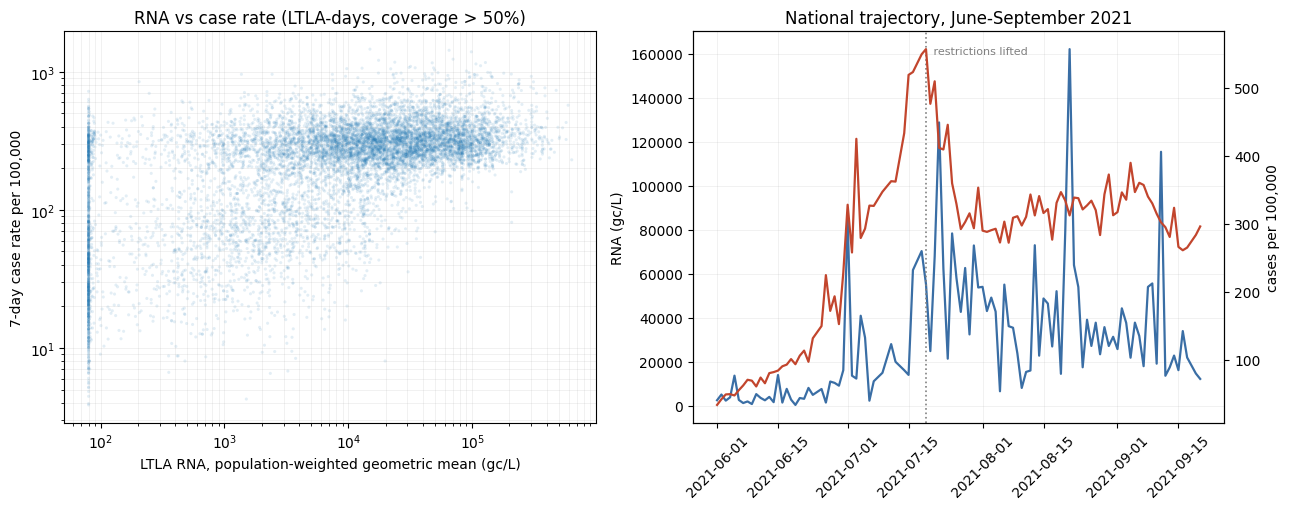

In [14]:
import matplotlib.pyplot as plt

sub = panel.dropna(subset=['rna_geom']).query('cases_roll7_rate > 0 and coverage_frac > 0.5')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

axes[0].scatter(sub.rna_geom, sub.cases_roll7_rate, s=5, alpha=0.12, edgecolor='none')
axes[0].set(xscale='log', yscale='log',
            xlabel='LTLA RNA, population-weighted geometric mean (gc/L)',
            ylabel='7-day case rate per 100,000',
            title='RNA vs case rate (LTLA-days, coverage > 50%)')
axes[0].grid(alpha=0.25, which='both', lw=0.5)

nat = (panel.dropna(subset=['rna_geom'])
            .groupby('date').apply(lambda t: pd.Series({
                'rna':  np.average(t.rna_geom, weights=t.pop_sampled),
                'rate': np.average(t.cases_roll7_rate.fillna(0), weights=t.ltla_pop)}),
                include_groups=False))
ax2 = axes[1]; ax3 = ax2.twinx()
ax2.plot(nat.index, nat.rna,  color='#3a6ea5', lw=1.6, label='RNA (geom. mean)')
ax3.plot(nat.index, nat.rate, color='#c2452d', lw=1.6, label='7-day case rate')
ax2.axvline(pd.Timestamp('2021-07-19'), color='grey', ls=':', lw=1.2)
ax2.text(pd.Timestamp('2021-07-20'), ax2.get_ylim()[1]*0.96, ' restrictions lifted',
         fontsize=8, color='grey', va='top')
ax2.set(ylabel='RNA (gc/L)', title='National trajectory, June-September 2021')
ax3.set_ylabel('cases per 100,000')
ax2.tick_params(axis='x', rotation=45); ax2.grid(alpha=0.25, lw=0.5)
fig.tight_layout(); plt.show()

In [15]:
work = panel.dropna(subset=['log10_rna_geom']).query('cases_roll7_rate > 0')
work = work.assign(log10_rate=np.log10(work.cases_roll7_rate))

print('Pearson correlation, log10 RNA vs log10 case rate')
print(f'  all LTLA-days           : {work.log10_rna_geom.corr(work.log10_rate):+.3f}  (n={len(work):,})')
hi = work[work.coverage_frac > 0.8]
print(f'  coverage > 80%          : {hi.log10_rna_geom.corr(hi.log10_rate):+.3f}  (n={len(hi):,})')
lo = work[work.coverage_frac < 0.3]
print(f'  coverage < 30%          : {lo.log10_rna_geom.corr(lo.log10_rate):+.3f}  (n={len(lo):,})')
print('\nIf the correlation strengthens with coverage, that supports coverage_frac as a')
print('model covariate or a sample-selection criterion, rather than a diagnostic only.')

Pearson correlation, log10 RNA vs log10 case rate
  all LTLA-days           : +0.579  (n=17,955)
  coverage > 80%          : +0.588  (n=6,374)
  coverage < 30%          : +0.517  (n=5,182)

If the correlation strengthens with coverage, that supports coverage_frac as a
model covariate or a sample-selection criterion, rather than a diagnostic only.


## 8. Save

In [16]:
panel.to_csv(OUT / 'rna_cases_panel.csv', index=False)
ltla_pop.to_csv(OUT / 'ltla_population.csv', index=False)
print(f'saved: rna_cases_panel.csv  ({len(panel):,} rows)')
print(f'saved: ltla_population.csv  ({len(ltla_pop)} rows)')

saved: rna_cases_panel.csv  (34,384 rows)
saved: ltla_population.csv  (329 rows)


## 8.1 What is in the finished dataset

`rna_cases_panel.csv` has one row for every local authority on every day of the study period: 307 authorities × 112 days = 34,384 rows.

### Identifying each row

| Column | Meaning |
|---|---|
| `LAD21CD` | The authority's ONS code, 2021 vintage. Unique identifier. |
| `LAD21NM` | The authority's name. |
| `date` | The day, from 2021-06-01 to 2021-09-20. |

### The case counts (what we are trying to predict)

| Column | Meaning |
|---|---|
| `cases` | New cases that day, by specimen date. Dips at weekends. |
| `cases_roll7_sum` | Cases over the seven days ending on this date. The main response variable used later. |
| `cases_roll7_rate` | The same figure per 100,000 residents, so authorities of different sizes are comparable. |

### The wastewater signal (what we are predicting from)

| Column | Meaning |
|---|---|
| `rna_arith` | RNA concentration for this authority on this day, gc/L. A population-weighted **average** of the works serving it. |
| `rna_geom` | The same, but averaging the logarithms instead — a geometric mean. Better suited to a quantity that spans several orders of magnitude. |
| `log10_rna_arith`, `log10_rna_geom` | Base-10 logarithms of the two columns above, since the models work on a log scale. |
| `rna_arith_roll7`, `rna_geom_roll7` | Seven-day trailing averages. Present because most days have no reading, and these fill the gaps. |

Both averaging methods are kept so the choice between them can be made later on evidence rather than assumption. They agree closely most of the time but differ by a factor of three at the 90th percentile of authority-days served by several works.

### Diagnostics (how much to trust each row)

| Column | Meaning |
|---|---|
| `n_stw` | How many sewage works contributed a reading that day. Ranges from 1 to 10. |
| `n_below` | How many of those readings were below the detection limit. |
| `pop_sampled` | The population covered by the works that reported that day. |
| `ltla_pop` | The authority's total resident population. |
| `coverage_frac` | `pop_sampled / ltla_pop` — the share of the authority's population inside a sampled catchment. **The single most useful column for judging a row.** A value of 0.9 means the reading covers almost everyone; 0.05 means it comes from a works serving a small corner of the authority. |

### Missing values

Wastewater columns are blank on days when no works serving that authority took a sample. This affects about half the rows and is a genuine property of the sampling programme, not a fault in the data. The `roll7` columns are blank far less often, since a seven-day window usually catches at least one sample.

Case columns are never blank. Where a day genuinely had no cases, the value is zero.

## 9. Summary

**What was built.** A complete authority × day table for 1 June to 20 September 2021: 307 authorities × 112 days, holding both versions of the wastewater signal, three case metrics, and the coverage figures needed to interpret them.

**What was checked.** Four values recomputed by hand all agree with the pipeline. Case totals match the raw file exactly, and the rolling rate calculated here agrees with UKHSA's published figures to within 0.4%.

### Things to keep in mind when using this dataset

- Only 52% of authority-days have a same-day wastewater reading. The 7-day column raises that to 96%, but only by smoothing.
- `coverage_frac` has a median of about 0.66, so a typical authority has two-thirds of its population inside a sampled catchment. Reweighting assumes the sampled part looks like the rest.
- Radlett and Plympton are still unresolved from notebook 01 and still contribute here.
- Case counts depend on testing. How much testing happened, and who chose to take a test, both changed over the summer of 2021. That affects the case counts but not the wastewater, which is part of why wastewater is interesting — but it is also a confounder.

### What comes next

`rna_cases_panel.csv` feeds **notebook 03**, which adds characteristics of each local authority — age structure, density and deprivation — and then **notebook 04**, which does the modelling.